<a href="https://colab.research.google.com/github/pr5952-creator/SVM-LINEAR-AND-NON-LINEAR/blob/main/SVM_NON_LINEAR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving data_banknote_authentication.txt to data_banknote_authentication.txt
First 5 rows:
   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0

Dataset shape: (1372, 5)

Missing values:
 variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Duplicate rows: 24

Training samples: 1078
Testing samples: 270

Nonlinear SVM trained successfully!

========== PERFORMANCE METRICS ==========
Accuracy: 0.9963
Precision: 0.9919
Recall: 1.0
F1-score: 0.9959
ROC-AUC: 1.0

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       148
           1       0.99      1.00      1.00       122

    accuracy                           1.00       270
   macro a

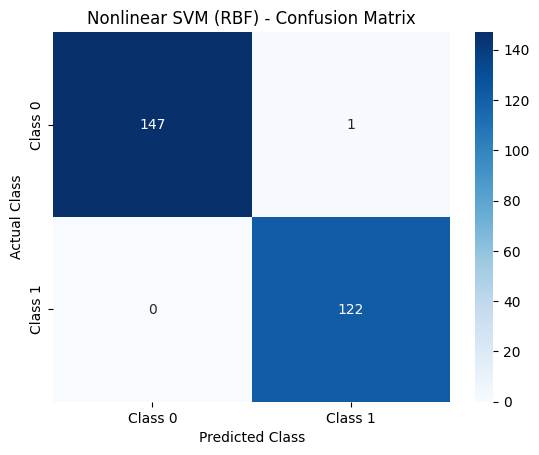

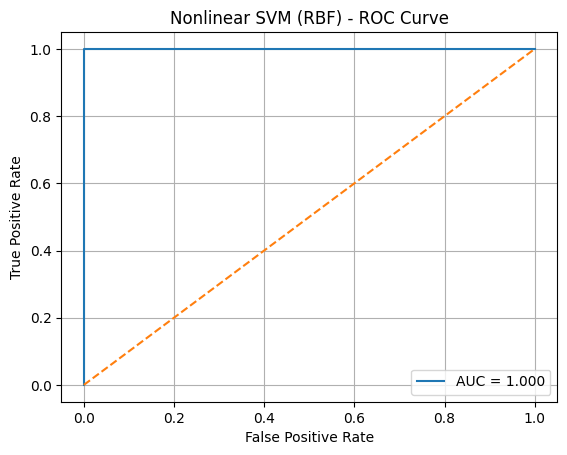

In [1]:

# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_auc_score, roc_curve
)

# 1. Load the TXT dataset
columns = ["variance", "skewness", "curtosis", "entropy", "class"]

uploaded = files.upload()

df = pd.read_csv(
    next(iter(uploaded)),
    header=None,
    names=columns
)

print("First 5 rows:")
print(df.head())

print("\nDataset shape:", df.shape)

# 2. Preprocessing
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().dropna()

X = df.drop("class", axis=1)
y = df["class"].astype(int)

# 3. Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 4. Feature scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 5. Train Nonlinear SVM using RBF kernel
model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

model.fit(X_train, y_train)

print("\nNonlinear SVM trained successfully!")

# 6. Make predictions
y_pred = model.predict(X_test)
y_scores = model.decision_function(X_test)

# 7. Performance metrics
print("\n========== PERFORMANCE METRICS ==========")

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_scores), 4))

# 8. Classification report
print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# 9. Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Nonlinear SVM (RBF) - Confusion Matrix")
plt.show()

# 10. ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_scores)

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {roc_auc_score(y_test, y_scores):.3f}"
)

plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Nonlinear SVM (RBF) - ROC Curve")
plt.legend()
plt.grid()
plt.show()
